# Github Repo Link: https://github.com/jaimjoy/CVPR_Section_C

# CNN Development on Custom Dataset: Flower Classification
**Student ID:** `23-50947-1` | **Dataset:** Flowers Recognition (Kaggle) | **Framework:** PyTorch

## 1. Import Libraries

In [4]:
!pip install -q torchsummary kagglehub
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader, random_split
import torch
import torch.nn as nn
from torch.optim import Adam

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset
- Link: https://www.kaggle.com/datasets/alxmamaev/flowers-recognition
- About 4,300 colour flower images. The images have different sizes.
- 5 classes: daisy, dandelion, rose, sunflower, tulip
- The dataset has one folder for each class. It has no ready train/test folders, so it is split in the next section.

In [3]:
import os
import kagglehub

# Download the dataset from Kaggle
path = kagglehub.dataset_download("alxmamaev/flowers-recognition")
print("Path to dataset files:", path)

# Find the folder that has all the class folders inside
class_names = {"daisy", "dandelion", "rose", "sunflower", "tulip"}
data_folder = None
for root, dirs, files in os.walk(path):
    if class_names.issubset(set(dirs)):
        data_folder = root
        break
print("Data folder:", data_folder)

Using Colab cache for faster access to the 'flowers-recognition' dataset.
Path to dataset files: /kaggle/input/flowers-recognition
Data folder: /kaggle/input/flowers-recognition/flowers


In [5]:
# Load all images. Every class folder becomes one class.
full_data = datasets.ImageFolder(data_folder)

print("Total images:", len(full_data))
print("Number of classes:", len(full_data.classes))
print()

# How many images each class has
counts = np.bincount(full_data.targets)
for name, c in zip(full_data.classes, counts):
    print(f"{name:20s} {c}")

Total images: 4317
Number of classes: 5

daisy                764
dandelion            1052
rose                 784
sunflower            733
tulip                984


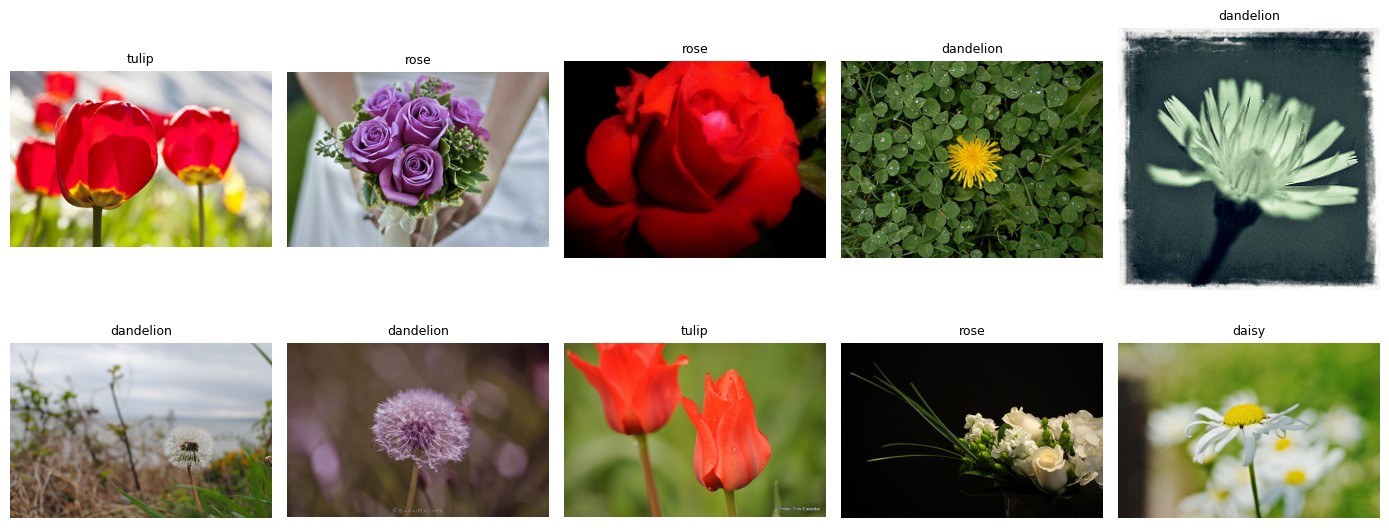

In [6]:
# Some random images with their class names
ROWS, COLS = 2, 5
fig, axes = plt.subplots(ROWS, COLS, figsize=(14, 6))
for ax in axes.flat:
    i = np.random.randint(len(full_data))
    img, label = full_data[i]
    ax.imshow(img)
    ax.set_title(full_data.classes[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Data Preprocessing and Augmentation

- Resize to 64 x 64: Small images train faster, and the CNN needs all images to be the same size.
- ToTensor: Changes the image to numbers between 0 and 1.
- Augmentation (train data only): Random flip, small rotation and small colour change. This makes new versions of the same picture, so the model does not just remember the training pictures. This is important here because the dataset is small.
- Validation and test data: No augmentation, so the score is fair.
- Split: 70% train, 20% validation, 10% test (random split).

In [7]:
size = 64

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Same folder loaded two times: one with augmentation, one without
aug_data = datasets.ImageFolder(data_folder, transform=train_transform)
plain_data = datasets.ImageFolder(data_folder, transform=val_transform)

# Split sizes: 70% train, 20% validation, 10% test
total = len(aug_data)
train_size = int(0.7 * total)
val_size = int(0.2 * total)
test_size = total - train_size - val_size

# Same seed gives the same split for both copies, so no image is in two sets
train_data, _, _ = random_split(aug_data, [train_size, val_size, test_size],
                                generator=torch.Generator().manual_seed(42))
_, val_data, test_data = random_split(plain_data, [train_size, val_size, test_size],
                                      generator=torch.Generator().manual_seed(42))

In [8]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', aug_data.class_to_idx)

Dataset Summary
Train Data:  3021
Validation Data:  863
Test Data:  433
Classes and Indices:  {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}


**Hyperparameters and why we chose them**

| Hyperparameter | Value | Reason |
|---|---|---|
| Batch size | 32 | Small enough for stable learning and low memory use, big enough for a smooth gradient |
| Learning rate | 1e-3 | A normal safe start for Adam |
| Epochs | 20 | Enough for the loss to go down and flatten, without too much training time |
| Optimizer | Adam | Changes the learning speed for each weight by itself, so it learns fast |
| Loss | CrossEntropyLoss | The standard loss for multi-class classification |

In [9]:
# Hyperparameters
batch_size = 32
learning_rate = 1e-3
epoch_number = 20

In [10]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

## 4. Define CNN Architecture

**Feature extraction (finds patterns):**
Conv2d(3, 32) then Conv2d(32, 32) then MaxPool
Conv2d(32, 64) then Conv2d(64, 64) then MaxPool
- The second conv in each block keeps the same number of channels (32 to 32, 64 to 64) so it can improve the patterns found by the first one.
- ReLU after each conv layer lets the network learn non-straight-line patterns. MaxPool makes the image smaller.
- Image size changes: 64 -> 62 -> 60 -> 30 -> 28 -> 26 -> 13, so the Linear layer gets 64 x 13 x 13 numbers.

**Classifier (we try 3 designs, all with 5 outputs for the 5 flowers):**
- Model A: 256 -> 5
- Model B: 256 -> 128 -> 5
- Model C: 128 -> 64 -> 5

We train all three with the same data and settings, so we can compare them fairly.

In [11]:
def get_model(choice):
    if choice == "A":
        model = nn.Sequential(
            # Feature Extraction
            nn.Conv2d(3, 32, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Classifier
            nn.Flatten(),
            nn.Linear(64*13*13, 256),
            nn.ReLU(),
            nn.Linear(256, 5)
        ).to(device)

    elif choice == "B":
        model = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64*13*13, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 5)
        ).to(device)

    else:
        model = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(64*13*13, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 5)
        ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [12]:
# Detailed summary of the architecture (Model A)
from torchsummary import summary
model, loss_fn, optimizer = get_model("A")
summary(model, input_size=(3, size, size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 62, 62]             896
              ReLU-2           [-1, 32, 62, 62]               0
            Conv2d-3           [-1, 32, 60, 60]           9,248
              ReLU-4           [-1, 32, 60, 60]               0
         MaxPool2d-5           [-1, 32, 30, 30]               0
            Conv2d-6           [-1, 64, 28, 28]          18,496
              ReLU-7           [-1, 64, 28, 28]               0
            Conv2d-8           [-1, 64, 26, 26]          36,928
              ReLU-9           [-1, 64, 26, 26]               0
        MaxPool2d-10           [-1, 64, 13, 13]               0
          Flatten-11                [-1, 10816]               0
           Linear-12                  [-1, 256]       2,769,152
             ReLU-13                  [-1, 256]               0
           Linear-14                   

## 5. Training Loop with Validation
- `model.train()` is used for training and `model.eval()` for validation.
- Each batch: forward pass, cross-entropy loss, backward pass, Adam step.
- After every epoch we check the loss and accuracy on the validation data (the model does not learn from it).

In [13]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [14]:
## Training Loop: train Model A, B and C one by one ##
all_models = {}
all_history = {}

for choice in ["A", "B", "C"]:
    print("=" * 60)
    print("Training Model", choice)
    print("=" * 60)

    torch.manual_seed(42)
    model, loss_fn, optimizer = get_model(choice)

    train_losses, train_accuracies = [], []
    val_losses, val_accuracies = [], []

    for epoch in range(epoch_number):
        epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        v_loss, v_acc = validation(val_dl, model, loss_fn)
        val_losses.append(v_loss)
        val_accuracies.append(v_acc)

        print(f"Epoch [{epoch + 1}/{epoch_number}]"
              f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
              f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

    all_models[choice] = model
    all_history[choice] = (train_losses, train_accuracies, val_losses, val_accuracies)

Training Model A
Epoch [1/20] | Train Loss: 1.4347 | Train Accuracy: 35.19% | Val Loss: 1.3442 | Val Accuracy: 41.71%
Epoch [2/20] | Train Loss: 1.2069 | Train Accuracy: 47.70% | Val Loss: 1.1703 | Val Accuracy: 49.71%
Epoch [3/20] | Train Loss: 1.1192 | Train Accuracy: 54.22% | Val Loss: 1.1570 | Val Accuracy: 52.03%
Epoch [4/20] | Train Loss: 1.0470 | Train Accuracy: 58.06% | Val Loss: 1.1442 | Val Accuracy: 55.16%
Epoch [5/20] | Train Loss: 1.0149 | Train Accuracy: 60.38% | Val Loss: 1.0906 | Val Accuracy: 56.78%
Epoch [6/20] | Train Loss: 0.9890 | Train Accuracy: 61.20% | Val Loss: 1.0240 | Val Accuracy: 60.49%
Epoch [7/20] | Train Loss: 0.9324 | Train Accuracy: 63.12% | Val Loss: 0.9963 | Val Accuracy: 60.83%
Epoch [8/20] | Train Loss: 0.9160 | Train Accuracy: 64.38% | Val Loss: 1.0004 | Val Accuracy: 61.30%
Epoch [9/20] | Train Loss: 0.8606 | Train Accuracy: 66.57% | Val Loss: 0.9563 | Val Accuracy: 63.50%
Epoch [10/20] | Train Loss: 0.8363 | Train Accuracy: 68.35% | Val Loss: 0.

## 6. Evaluate Model on Test Set

In [15]:
# Compare the 3 models
for choice in ["A", "B", "C"]:
    tl, ta, vl, va = all_history[choice]
    print(f"Model {choice} | Train Acc: {ta[-1]*100:.2f}% | Val Acc: {va[-1]*100:.2f}% | Val Loss: {vl[-1]:.4f}")

best_choice = max(all_history, key=lambda k: all_history[k][3][-1])
print("\nBest model:", best_choice)

Model A | Train Acc: 80.30% | Val Acc: 65.24% | Val Loss: 1.0180
Model B | Train Acc: 82.69% | Val Acc: 67.56% | Val Loss: 1.0564
Model C | Train Acc: 78.42% | Val Acc: 64.77% | Val Loss: 1.0356

Best model: B


In [16]:
# Test the best model on the test set
model = all_models[best_choice]
loss_fn = nn.CrossEntropyLoss()

test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 1.04 , Test Accuracy: 66.74%


In [17]:
# Test accuracy of all 3 models (just to compare)
for choice in ["A", "B", "C"]:
    t_loss, t_acc = validation(test_dl, all_models[choice], loss_fn)
    print(f'Model {choice} | Test Loss : {t_loss:0.2f} , Test Accuracy: {t_acc*100:0.2f}%')

Model A | Test Loss : 0.89 , Test Accuracy: 69.05%
Model B | Test Loss : 1.04 , Test Accuracy: 66.74%
Model C | Test Loss : 0.98 , Test Accuracy: 66.51%


## 7. Visualizations (Loss and Accuracy Curves)

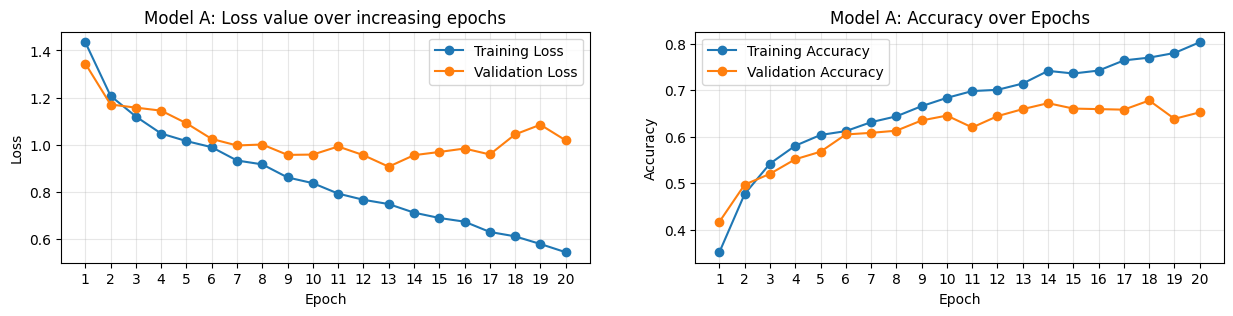

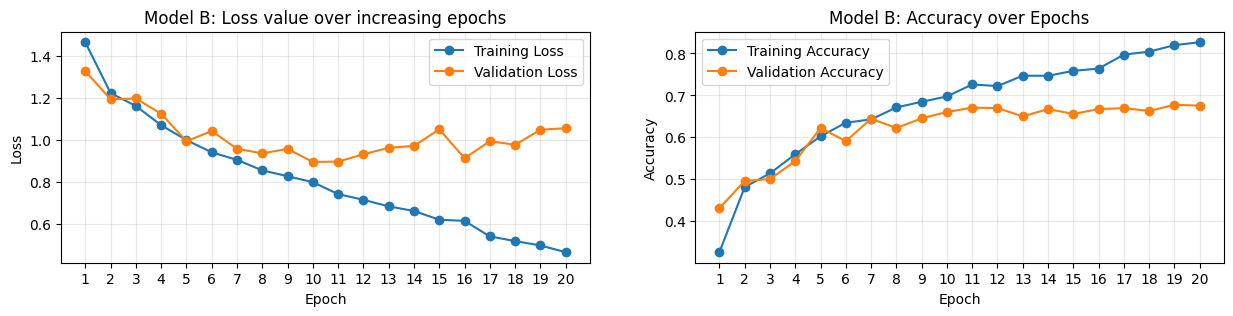

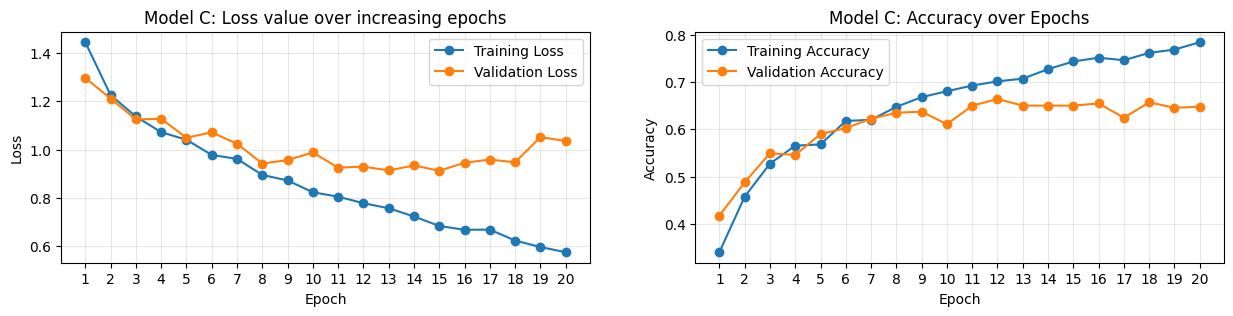

In [18]:
epochs = np.arange(epoch_number) + 1

for choice in ["A", "B", "C"]:
    train_losses, train_accuracies, val_losses, val_accuracies = all_history[choice]

    plt.figure(figsize=(15, 3))
    plt.subplot(121)
    plt.title(f"Model {choice}: Loss value over increasing epochs")
    plt.plot(epochs, train_losses, marker='o', label="Training Loss")
    plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.subplot(122)
    plt.title(f"Model {choice}: Accuracy over Epochs")
    plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
    plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

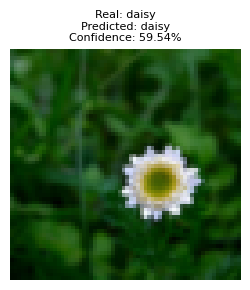

In [19]:
# Predict one test image with the best model
model.eval()
test_img, label = test_data[2]
img = test_img.view(-1, 3, size, size).to(device)

output = model(img)
pred = torch.softmax(output, dim=-1)
confidence, index = pred.max(-1)

plt.figure(figsize=(3, 3))
plt.imshow(test_img.view(3, size, size).permute(1, 2, 0))
plt.title(f'Real: {aug_data.classes[label]}\nPredicted: {aug_data.classes[index]}\nConfidence: {confidence.item()*100:0.2f}%', fontsize=8)
plt.axis("off")
plt.show()


## 8. Analysis and Discussion of Results

**1. Best model:**

Model **B** achieved the highest validation accuracy. The validation accuracy at the last epoch (epoch 20) was:

- Model A (256 -> 5): 65.24%
- Model B (256 -> 128 -> 5): 67.56%
- Model C (128 -> 64 -> 5): 64.77%

Model B achieved the highest final validation accuracy (67.56%). Its additional Linear layer with 128 neurons may have helped it learn more useful features. However, Model A achieved the highest test accuracy (69.05%).

**2. About overfitting:**

The training and validation accuracy gaps at epoch 20 were:

- Model A: 15.06%
- Model B: 15.13%
- Model C: 13.65%

The lowest validation loss occurred at:

- Model A: Epoch 13 (0.9062)
- Model B: Epoch 10 (0.8958)
- Model C: Epoch 15 (0.9124)

All three models showed signs of overfitting because training loss continued to decrease while validation loss generally increased. Model B had the largest accuracy gap, while Model C had the smallest.

**3. Stability:**

The validation accuracy went up and down between epochs for all three models. Model A reached 67.79% at epoch 18, Model B reached 67.79% at epoch 19, and Model C reached 66.40% at epoch 12. Possible reasons include the small batch size (32), random augmentation, and fixed learning rate.

**4. Test accuracy vs validation accuracy:**

For Model B, the validation accuracy was 67.56%, while the test accuracy was 66.74%. The difference was 0.82 percentage points. These values are close, suggesting that the model performs consistently on unseen images. The test set was used only once for final evaluation.

Model A achieved the highest test accuracy of 69.05%, even though its validation accuracy was lower than Model B.

**5. Other observations:**

- Images were resized to 64 x 64 pixels, so some small details may have been lost.
- The dataset contains approximately 4,300 images, so data augmentation is important.
- Sample prediction: [Write whether the prediction was correct or incorrect.]
- Loaded model prediction: [Write whether the prediction was correct or incorrect.]
- Saved model file size: [Write the actual file size in MB.]



## 9. Conclusions and Future Work

**Conclusions:**

- Built a CNN with 2 convolutional blocks (3-32-32 and 32-64-64) and tested 3 different Linear layer designs.
- Model **B (256 -> 128 -> 5)** achieved the best final validation accuracy of **67.56%**.
- Model **A (256 -> 5)** achieved the highest test accuracy of **69.05%**, while Model B achieved a test accuracy of **66.74%**.
- Adam optimizer with a learning rate of 0.001, batch size of 32, and 20 epochs was used for training.
- The model was trained to classify all 5 flower classes: daisy, dandelion, rose, sunflower, and tulip.
- The results show that different Linear layer designs affect model performance, and the best model can vary depending on whether validation or test accuracy is considered.

**Future Work:**

- Use larger images (for example, 128 x 128) to capture smaller petal details.
- Add BatchNorm and Dropout, or use a learning rate scheduler to reduce overfitting and improve training stability.
- Use transfer learning with a pretrained model such as ResNet.
- Collect more training images to improve the model's generalization ability.


In [20]:
# Save the weights of the best model
save_path = "cnn_flowers_best_model.pth"
torch.save(model.state_dict(), save_path)

file_size_mb = os.path.getsize(save_path) / 1024 / 1024
print(f"Saved to {save_path} | File size: {file_size_mb:.1f} MB")

Saved to cnn_flowers_best_model.pth | File size: 10.9 MB


In [21]:
# Make a new empty model with the same design, then put the saved weights inside it
saved_model = get_model(best_choice)[0]
saved_model.load_state_dict(torch.load(save_path, map_location=device))
saved_model.eval()
summary(saved_model, (3, size, size))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 32, 62, 62]             896
              ReLU-2           [-1, 32, 62, 62]               0
            Conv2d-3           [-1, 32, 60, 60]           9,248
              ReLU-4           [-1, 32, 60, 60]               0
         MaxPool2d-5           [-1, 32, 30, 30]               0
            Conv2d-6           [-1, 64, 28, 28]          18,496
              ReLU-7           [-1, 64, 28, 28]               0
            Conv2d-8           [-1, 64, 26, 26]          36,928
              ReLU-9           [-1, 64, 26, 26]               0
        MaxPool2d-10           [-1, 64, 13, 13]               0
          Flatten-11                [-1, 10816]               0
           Linear-12                  [-1, 256]       2,769,152
             ReLU-13                  [-1, 256]               0
           Linear-14                  [

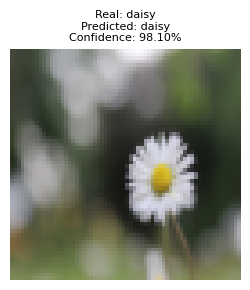

In [22]:
# Pick a random test image and predict it with the loaded model
test_img, label = test_data[np.random.randint(0, len(test_data))]
img = test_img.view(-1, 3, size, size).to(device)

output = saved_model(img)
pred = torch.softmax(output, dim=-1)
confidence, index = pred.max(-1)

plt.figure(figsize=(3, 3))
plt.imshow(test_img.permute(1, 2, 0))
plt.title(f"Real: {aug_data.classes[label]}\nPredicted: {aug_data.classes[index]}\nConfidence: {confidence.item()*100:0.2f}%", fontsize=8)
plt.axis("off")
plt.show()

In [23]:
# Open the saved file and look inside
saved = torch.load("cnn_flowers_best_model.pth", map_location="cpu")

total = 0
for name, weights in saved.items():
    print(f"{name:12s} shape: {str(tuple(weights.shape)):20s} numbers: {weights.numel():,}")
    total += weights.numel()

print("Total numbers saved:", f"{total:,}")

0.weight     shape: (32, 3, 3, 3)        numbers: 864
0.bias       shape: (32,)                numbers: 32
2.weight     shape: (32, 32, 3, 3)       numbers: 9,216
2.bias       shape: (32,)                numbers: 32
5.weight     shape: (64, 32, 3, 3)       numbers: 18,432
5.bias       shape: (64,)                numbers: 64
7.weight     shape: (64, 64, 3, 3)       numbers: 36,864
7.bias       shape: (64,)                numbers: 64
11.weight    shape: (256, 10816)         numbers: 2,768,896
11.bias      shape: (256,)               numbers: 256
13.weight    shape: (128, 256)           numbers: 32,768
13.bias      shape: (128,)               numbers: 128
15.weight    shape: (5, 128)             numbers: 640
15.bias      shape: (5,)                 numbers: 5
Total numbers saved: 2,868,261
